In [51]:
import torch
import yaml
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt

In [52]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [65]:
with open("plant_model.yaml", "r") as f:
    config = yaml.safe_load(f)
config

{'model': {'name': 'densenet',
  'format': 'torchscript',
  'file': 'plant_model.pt',
  'input': {'channels': 3, 'height': 224, 'width': 224, 'color_mode': 'RGB'},
  'preprocessing': {'resize': [224, 224],
   'convert_to_tensor': True,
   'normalize': {'mean': [0.485, 0.456, 0.406],
    'std': [0.229, 0.224, 0.225]}}},
 'classes': ['Apple___Apple_scab',
  'Apple___Black_rot',
  'Apple___Cedar_apple_rust',
  'Apple___healthy',
  'Blueberry___healthy',
  'Cherry_(including_sour)___Powdery_mildew',
  'Cherry_(including_sour)___healthy',
  'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
  'Corn_(maize)___Common_rust_',
  'Corn_(maize)___Northern_Leaf_Blight',
  'Corn_(maize)___healthy',
  'Grape___Black_rot',
  'Grape___Esca_(Black_Measles)',
  'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
  'Grape___healthy',
  'Orange___Haunglongbing_(Citrus_greening)',
  'Peach___Bacterial_spot',
  'Peach___healthy',
  'Pepper,_bell___Bacterial_spot',
  'Pepper,_bell___healthy',
  'Potato___Early_

In [27]:
classes = config["classes"]

In [28]:
model = torch.jit.load(
    config["model"]["file"],
    map_location=device
)

In [29]:
model.eval()

RecursiveScriptModule(
  original_name=densenet
  (stem): RecursiveScriptModule(
    original_name=Sequential
    (0): RecursiveScriptModule(original_name=Conv2d)
    (1): RecursiveScriptModule(original_name=BatchNorm2d)
    (2): RecursiveScriptModule(original_name=ReLU)
  )
  (block1): RecursiveScriptModule(
    original_name=denseblock
    (layers): RecursiveScriptModule(
      original_name=ModuleList
      (0): RecursiveScriptModule(
        original_name=denselayer
        (layer): RecursiveScriptModule(
          original_name=Sequential
          (0): RecursiveScriptModule(original_name=BatchNorm2d)
          (1): RecursiveScriptModule(original_name=ReLU)
          (2): RecursiveScriptModule(original_name=Conv2d)
        )
      )
      (1): RecursiveScriptModule(
        original_name=denselayer
        (layer): RecursiveScriptModule(
          original_name=Sequential
          (0): RecursiveScriptModule(original_name=BatchNorm2d)
          (1): RecursiveScriptModule(original_

In [67]:
input_config = config["model"]["input"]

transform = transforms.Compose([
    transforms.Resize((
        input_config["height"],
        input_config["width"]
    )),
    transforms.ToTensor(),
    transforms.Normalize(
        config["model"]['preprocessing']['normalize']['mean'],
        config["model"]['preprocessing']['normalize']['std']
    )
])

In [64]:
def predict(image_path):
    org_image = Image.open(image_path).convert("RGB")
    image = transform(org_image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(image)
        probabilities = torch.softmax(outputs, dim=1)
        confidence, prediction = probabilities.max(dim=1)
        
    plt.imshow(org_image)

    print("Predicted class:", classes[prediction.item()])
    print(f"Confidence: {confidence.item() * 100:.2f}%")

Predicted class: Cherry_(including_sour)___Powdery_mildew
Confidence: 98.37%


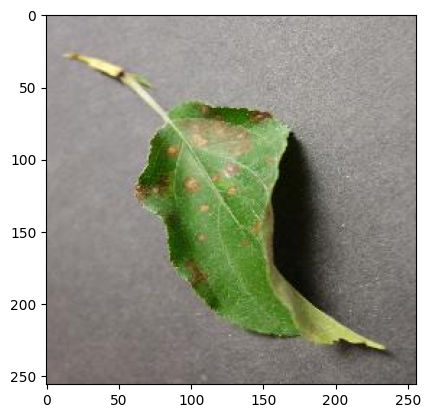

In [48]:
predict("../New Plant Diseases Dataset(Augmented)/test/test/AppleCedarRust3.JPG")